# 🧬 03 — Featurização e Análise Exploratória (EDA): Receptor de Adenosina A2A
**Projeto:** MultiTarget BioPredict  
**Fase:** 2 — Featurização e Análise Exploratória do Espaço Químico  
**Autor:** Raphael Pires

---

## 🎯 Contexto e Objetivos

O **Receptor de Adenosina $A_{2A}$** (*ADORA2A*) é o nosso alvo biológico de eficácia terapêutica (modulação da fadiga no SNC e imunoterapia tumoral). Na Fase 1, construímos uma base curada de alta qualidade com **1.364 moléculas únicas** (`data/processed/a2a_curated.csv`).

### Escopo deste Caderno:
1. **Featurização Vetorizada Concorrente:**
   - Cálculo de 6 descritores físico-químicos 2D fundamentais (Lipinski & Veber): `MolWt`, `MolLogP`, `TPSA`, `NumHDonors`, `NumHAcceptors`, `NumRotatableBonds`.
   - Geração de *Morgan Fingerprints* (ECFP4 com raio 2 e 1024 bits), alocados estritamente em matrizes `numpy.uint8` para economia de memória de 8x.
2. **Análise Exploratória de Dados (EDA):**
   - Distribuição estatística dos descritores físico-químicos.
   - Correlação paramétrica (Pearson) e não-paramétrica (Spearman) entre as propriedades e a potência biológica ($pIC_{50}$).
   - Avaliação da "Druggability" segundo a Regra dos 5 de Lipinski e critérios de Veber.
   - Análise de fragmentos moleculares diferenciais (bits de Morgan mais prevalentes em compostos potentes).
3. **Mapeamento do Espaço Químico via Redução de Dimensionalidade:**
   - Projeção PCA (2 componentes principais) dos compostos, visualizando o gradiente de potência $pIC_{50}$.
4. **Persistência dos Dados Featurizados:**
   - Exportação em formato de alta performance `data/processed/a2a_featurized.parquet` pronto para os algoritmos de regressão da Fase 3.

In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from IPython.display import display

# Adiciona a raiz do projeto ao path
project_root = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from src.chem_utils import (
    DESCRIPTOR_NAMES,
    FEATURE_NAMES,
    FINGERPRINT_NAMES,
    featurize_dataframe
)
from src.data_utils import PROCESSED_DIR

# Configuração estética dos gráficos
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'Arial'
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['figure.dpi'] = 110

print(f"Diretório raiz do projeto: {project_root}")
print(f"Total de atributos planejados: {len(FEATURE_NAMES)} (6 descritores 2D + 1024 bits ECFP4)")

Diretório raiz do projeto: C:\Users\Raphael\Documents\BioPredicta
Total de atributos planejados: 1030 (6 descritores 2D + 1024 bits ECFP4)


## 1. Carga dos Dados Curados e Featurização Molecular

Carregamos o dataset curado gerado na Fase 1 (`a2a_curated.csv`). Se a matriz featurizada já tiver sido pré-computada em disco (`a2a_featurized.parquet`), carregamos diretamente com carregamento instantâneo via `pyarrow`; caso contrário, executamos a featurização completa via `featurize_dataframe`.

In [2]:
parquet_path = PROCESSED_DIR / "a2a_featurized.parquet"
curated_path = PROCESSED_DIR / "a2a_curated.csv"

if parquet_path.exists():
    print(f"Carregando dataset featurizado diretamente do cache: {parquet_path}")
    df_a2a = pd.read_parquet(parquet_path)
else:
    print(f"Featurizando dataset a partir de: {curated_path}")
    df_curated = pd.read_csv(curated_path)
    df_a2a = featurize_dataframe(df_curated)
    df_a2a.to_parquet(parquet_path, index=False)

print(f"Dimensões finais da matriz A2A: {df_a2a.shape}")
print(f"Exemplo de tipo de dado dos Morgan bits: {df_a2a['fp_0'].dtype}")

# Amostra das primeiras linhas com as colunas principais
sample_cols = ["molecule_chembl_id", "pIC50"] + list(DESCRIPTOR_NAMES) + ["fp_0", "fp_1", "fp_2"]
df_a2a[sample_cols].head()

Carregando dataset featurizado diretamente do cache: C:\Users\Raphael\Documents\BioPredicta\data\processed\a2a_featurized.parquet


Dimensões finais da matriz A2A: (1364, 1035)
Exemplo de tipo de dado dos Morgan bits: uint8


,molecule_chembl_id,pIC50,MolWt,MolLogP,TPSA,NumHDonors,NumHAcceptors,NumRotatableBonds,fp_0,fp_1,fp_2
0,CHEMBL3958838,11.7212,353.407,3.5492,99.09,2,8,5,0,0,0
1,CHEMBL5182250,11.1198,324.369,2.9909,102.75,2,8,4,0,1,0
2,CHEMBL4161758,11.1066,329.410,3.6021,89.86,2,8,4,0,0,0
3,CHEMBL4172399,11.0969,313.342,3.1336,103.00,2,8,4,0,0,0
4,CHEMBL3904408,11.0809,353.407,3.5492,99.09,2,8,5,0,0,0


## 2. Análise Estatística e Distribuição dos Descritores 2D

Avaliamos as propriedades físico-químicas calculadas pelo RDKit para os 1.364 ligantes de $A_{2A}$:
- **`MolWt`**: Massa molecular (g/mol).
- **`MolLogP`**: Coeficiente de partição octanol/água (Crippen).
- **`TPSA`**: Área de superfície polar topológica (Å²).
- **`NumHDonors`**: Doadores de ligação de hidrogênio.
- **`NumHAcceptors`**: Receptores de ligação de hidrogênio.
- **`NumRotatableBonds`**: Ligações químicas rotacionáveis.

In [3]:
desc_df = df_a2a[list(DESCRIPTOR_NAMES)]
stats_summary = desc_df.describe().T[['mean', 'std', 'min', '25%', '50%', '75%', 'max']]
stats_summary.columns = ['Média', 'Desvio Padrão', 'Mínimo', '1º Quartil', 'Mediana', '3º Quartil', 'Máximo']

print("Resumo Estatístico dos Descritores 2D (Ligantes A2A):")
display(stats_summary.round(2))

Resumo Estatístico dos Descritores 2D (Ligantes A2A):


,Média,Desvio Padrão,Mínimo,1º Quartil,Mediana,3º Quartil,Máximo
MolWt,419.03,82.66,180.17,367.43,415.49,465.77,878.14
MolLogP,3.28,1.01,-1.84,2.69,3.29,3.89,7.15
TPSA,103.11,27.08,9.49,85.22,100.11,119.62,241.95
NumHDonors,1.75,1.02,0.00,1.00,2.00,2.00,8.00
NumHAcceptors,6.78,1.59,1.00,6.00,7.00,8.00,16.00
NumRotatableBonds,5.08,2.67,0.00,4.00,5.00,6.00,31.00


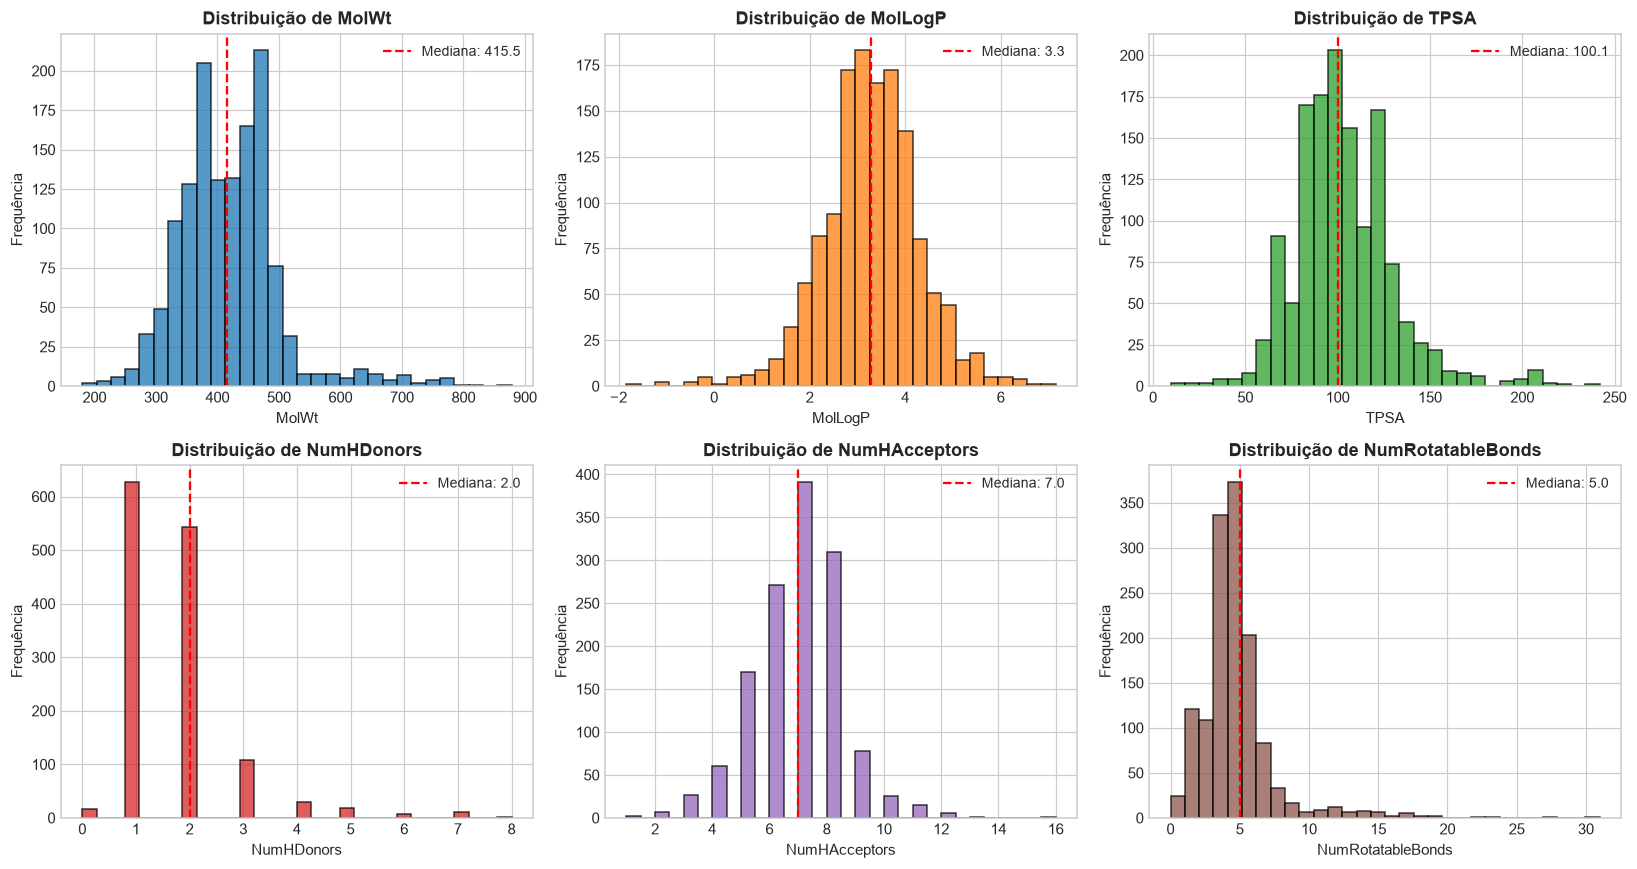

In [4]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes = axes.flatten()

colors = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728', '#9467bd', '#8c564b']

for i, col in enumerate(DESCRIPTOR_NAMES):
    ax = axes[i]
    ax.hist(df_a2a[col], bins=30, color=colors[i], edgecolor='black', alpha=0.75)
    ax.axvline(df_a2a[col].median(), color='red', linestyle='--', linewidth=1.5, label=f"Mediana: {df_a2a[col].median():.1f}")
    ax.set_title(f"Distribuição de {col}", fontsize=12, fontweight='bold')
    ax.set_xlabel(col, fontsize=10)
    ax.set_ylabel("Frequência", fontsize=10)
    ax.legend(fontsize=9)

plt.tight_layout()
plt.show()

## 3. Correlação Físico-Química com a Afinidade ($pIC_{50}$)

Avaliamos o grau de associação entre as propriedades físico-químicas calculadas e a potência de inibição/ligação ($pIC_{50}$):
- **Correlação de Pearson ($r$):** Associação linear.
- **Correlação de Spearman ($ho$):** Associação monotônica não-paramétrica.

Tabela de Correlações com a Potência pIC50:


,Descritor,Pearson (r),p-valor (Pearson),Spearman (rho),p-valor (Spearman)
0,TPSA,0.236,9.29e-19,0.280,4.57e-26
1,MolWt,0.217,4.62e-16,0.279,9.16e-26
2,NumHAcceptors,0.202,4.87e-14,0.209,6.33e-15
3,NumHDonors,0.005,8.52e-01,-0.010,7.11e-01
4,MolLogP,-0.055,4.37e-02,-0.097,3.18e-04
5,NumRotatableBonds,-0.074,6.48e-03,-0.099,2.59e-04


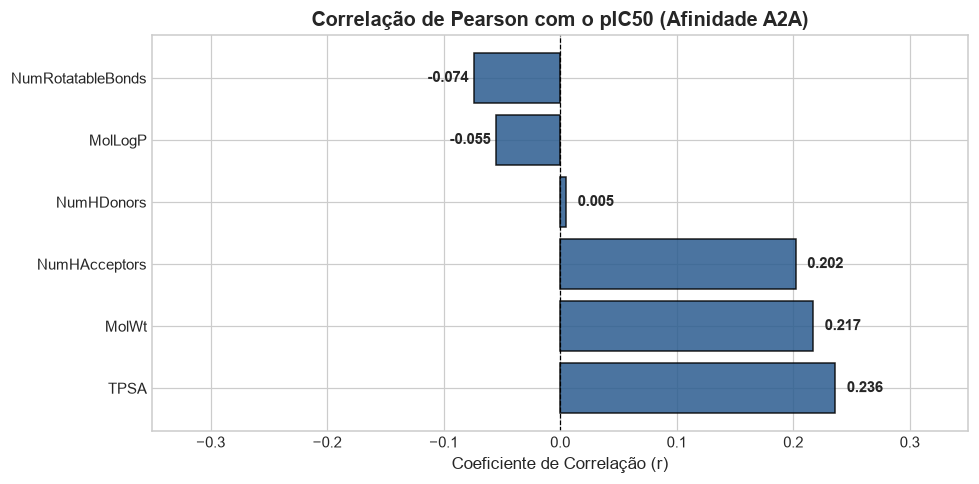

In [5]:
corr_data = []
for desc in DESCRIPTOR_NAMES:
    r_pearson, p_pearson = stats.pearsonr(df_a2a[desc], df_a2a['pIC50'])
    rho_spearman, p_spearman = stats.spearmanr(df_a2a[desc], df_a2a['pIC50'])
    corr_data.append({
        'Descritor': desc,
        'Pearson (r)': round(r_pearson, 3),
        'p-valor (Pearson)': f"{p_pearson:.2e}",
        'Spearman (rho)': round(rho_spearman, 3),
        'p-valor (Spearman)': f"{p_spearman:.2e}"
    })

df_corr = pd.DataFrame(corr_data).sort_values(by='Pearson (r)', ascending=False).reset_index(drop=True)

print("Tabela de Correlações com a Potência pIC50:")
display(df_corr)

# Gráfico de barras horizontais de correlação
plt.figure(figsize=(9, 4.5))
bars = plt.barh(df_corr['Descritor'], df_corr['Pearson (r)'], color='#2b5c8f', edgecolor='black', alpha=0.85)
plt.axvline(0, color='black', linewidth=0.8, linestyle='--')
plt.title("Correlação de Pearson com o pIC50 (Afinidade A2A)", fontsize=13, fontweight='bold')
plt.xlabel("Coeficiente de Correlação (r)", fontsize=11)

for bar in bars:
    w = bar.get_width()
    plt.text(w + (0.01 if w >= 0 else -0.04), bar.get_y() + bar.get_height()/2, f"{w:.3f}", 
             va='center', fontsize=10, fontweight='bold')

plt.xlim(-0.35, 0.35)
plt.tight_layout()
plt.show()

## 4. Avaliação de Druggability: Regra de Lipinski e Critérios de Veber

Em química medicinal, a **Regra dos 5 de Lipinski (Ro5)** prevê a probabilidade de uma molécula ser viável como fármaco de administração oral:
1. Massa Molecular ($	ext{MolWt}$) $\le 500 	ext{ Da}$
2. Lipofilicidade ($	ext{MolLogP}$) $\le 5{,}0$
3. Doadores de Ligação de H ($	ext{NumHDonors}$) $\le 5$
4. Aceptores de Ligação de H ($	ext{NumHAcceptors}$) $\le 10$

Critérios adicionais de **Veber**:
5. Área Polar ($	ext{TPSA}$) $\le 140 	ext{ \AA}^2$
6. Ligações Rotacionáveis ($	ext{NumRotatableBonds}$) $\le 10$

In [6]:
def calculate_lipinski_violations(row):
    v = 0
    if row['MolWt'] > 500: v += 1
    if row['MolLogP'] > 5: v += 1
    if row['NumHDonors'] > 5: v += 1
    if row['NumHAcceptors'] > 10: v += 1
    return v

def calculate_veber_violations(row):
    v = 0
    if row['TPSA'] > 140: v += 1
    if row['NumRotatableBonds'] > 10: v += 1
    return v

df_a2a['lipinski_violations'] = df_a2a.apply(calculate_lipinski_violations, axis=1)
df_a2a['veber_violations'] = df_a2a.apply(calculate_veber_violations, axis=1)

lip_counts = df_a2a['lipinski_violations'].value_counts().sort_index()
lip_props = df_a2a['lipinski_violations'].value_counts(normalize=True).sort_index().mul(100).round(1)

lip_summary = pd.DataFrame({
    'Violações Lipinski': lip_counts.index,
    'Contagem': lip_counts.values,
    'Percentual (%)': lip_props.values,
    'Status Farmacológico': ['Em total conformidade (0)', 'Aceitável (1)', 'Baixa biodisponibilidade (2)', 'Não-fármaco (>=3)'][:len(lip_counts)]
})

print("Conformidade com a Regra dos 5 de Lipinski (Base A2A):")
display(lip_summary)

Conformidade com a Regra dos 5 de Lipinski (Base A2A):


,Violações Lipinski,Contagem,Percentual (%),Status Farmacológico
0,0,1214,89.0,Em total conformidade (0)
1,1,97,7.1,Aceitável (1)
2,2,39,2.9,Baixa biodisponibilidade (2)
3,3,14,1.0,Não-fármaco (>=3)


## 5. Análise de Subestruturas: Bits de Morgan Enriquecidos em Alta Potência

Comparamos a prevalência dos bits de Morgan (ECFP4) entre duas populações:
- 🟢 **Alta Potência:** $pIC_{50} \ge 6.5$ (1.031 moléculas)
- 🟡🔴 **Moderada / Baixa Potência:** $pIC_{50} < 6.5$ (333 moléculas)

Essa análise identifica fragmentos químicos correlacionados à farmacoforia de ancoragem no receptor $A_{2A}$.

In [7]:
high_pot = df_a2a[df_a2a['pIC50'] >= 6.5]
low_pot = df_a2a[df_a2a['pIC50'] < 6.5]

fp_cols = list(FINGERPRINT_NAMES)

freq_high = high_pot[fp_cols].mean(axis=0)
freq_low = low_pot[fp_cols].mean(axis=0)

diff_freq = (freq_high - freq_low).sort_values(ascending=False)

top_bits_df = pd.DataFrame({
    'Bit': diff_freq.index[:10],
    'Frequência Alta Potência (%)': freq_high[diff_freq.index[:10]].mul(100).round(1).values,
    'Frequência Baixa Potência (%)': freq_low[diff_freq.index[:10]].mul(100).round(1).values,
    'Diferença Enriquecimento (%)': diff_freq.values[:10] * 100
})

print("Top 10 Bits de Morgan Mais Enriquecidos em Compostos Potentes de A2A:")
display(top_bits_df.round(1))

Top 10 Bits de Morgan Mais Enriquecidos em Compostos Potentes de A2A:


,Bit,Frequência Alta Potência (%),Frequência Baixa Potência (%),Diferença Enriquecimento (%)
0,fp_904,50.6,10.8,39.8
1,fp_699,46.2,7.4,38.8
2,fp_1,41.9,11.7,30.2
3,fp_283,35.2,6.1,29.2
4,fp_37,29.1,2.2,27.0
5,fp_603,30.4,3.9,26.5
6,fp_474,34.0,7.8,26.2
7,fp_964,30.8,5.6,25.2
8,fp_690,29.7,4.8,24.9
9,fp_1019,44.0,19.5,24.6


## 6. Mapeamento do Espaço Químico via Redução de Dimensionalidade (PCA)

Projetamos o espaço molecular multivariado dos 6 descritores 2D fundamentais em um plano bidimensional via **Análise de Componentes Principais (PCA)** com padronização por *StandardScaler*.

Variância explicada: PC1 = 60.5%, PC2 = 20.9% (Total acumulado: 81.4%)


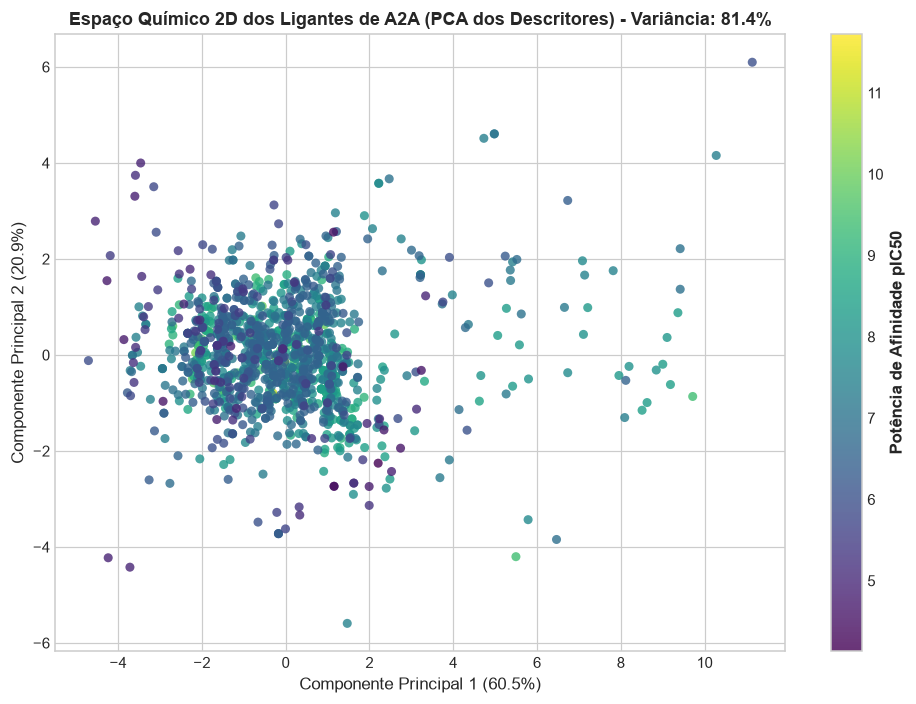

In [8]:
scaler = StandardScaler()
X_desc_scaled = scaler.fit_transform(df_a2a[list(DESCRIPTOR_NAMES)])

pca = PCA(n_components=2, random_state=42)
pca_coords = pca.fit_transform(X_desc_scaled)

df_a2a['PCA_1'] = pca_coords[:, 0]
df_a2a['PCA_2'] = pca_coords[:, 1]

var_exp = pca.explained_variance_ratio_ * 100
print(f"Variância explicada: PC1 = {var_exp[0]:.1f}%, PC2 = {var_exp[1]:.1f}% (Total acumulado: {sum(var_exp):.1f}%)")

plt.figure(figsize=(9, 6.5))
scatter = plt.scatter(
    df_a2a['PCA_1'],
    df_a2a['PCA_2'],
    c=df_a2a['pIC50'],
    cmap='viridis',
    alpha=0.8,
    s=35,
    edgecolors='none'
)
cbar = plt.colorbar(scatter)
cbar.set_label('Potência de Afinidade pIC50', fontsize=11, fontweight='bold')

plt.title(f"Espaço Químico 2D dos Ligantes de A2A (PCA dos Descritores) - Variância: {sum(var_exp):.1f}%", fontsize=12, fontweight='bold')
plt.xlabel(f"Componente Principal 1 ({var_exp[0]:.1f}%)", fontsize=11)
plt.ylabel(f"Componente Principal 2 ({var_exp[1]:.1f}%)", fontsize=11)
plt.tight_layout()
plt.show()

## 7. Persistência dos Dados Featurizados

Garantimos a persistência do conjunto final featurizado em `data/processed/a2a_featurized.parquet` (armazenamento colunar compacto e veloz) e `data/processed/a2a_featurized.csv`.

In [9]:
out_parquet = PROCESSED_DIR / "a2a_featurized.parquet"
out_csv = PROCESSED_DIR / "a2a_featurized.csv"

# Remove colunas auxiliares de análise exploratória mantendo colunas do pipeline
pipeline_cols = [c for c in df_a2a.columns if c not in ['PCA_1', 'PCA_2', 'lipinski_violations', 'veber_violations']]

df_a2a[pipeline_cols].to_parquet(out_parquet, index=False)
df_a2a[pipeline_cols].to_csv(out_csv, index=False)

print(f"Dataset A2A featurizado salvo com sucesso!")
print(f"  Parquet: {out_parquet} ({out_parquet.stat().st_size / (1024*1024):.2f} MB)")
print(f"  CSV:     {out_csv} ({out_csv.stat().st_size / (1024*1024):.2f} MB)")
print(f"  Formato da Matriz: {df_a2a[pipeline_cols].shape} (1.364 amostras x 1.035 colunas)")

Dataset A2A featurizado salvo com sucesso!
  Parquet: C:\Users\Raphael\Documents\BioPredicta\data\processed\a2a_featurized.parquet (0.64 MB)
  CSV:     C:\Users\Raphael\Documents\BioPredicta\data\processed\a2a_featurized.csv (2.85 MB)
  Formato da Matriz: (1364, 1035) (1.364 amostras x 1.035 colunas)
